In [3]:
from pathlib import Path 
import pandas as pd
import matplotlib as plt


import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [4]:
# Defining main paths

data_p = Path('data')

case1_p = data_p/'case1'
test1_p = case1_p/'test1.csv'
train1_p = case1_p/'train1.csv'

case2_p = data_p/'case2'
test2_p = case2_p/'test2.csv' 
train2_p = case2_p/'train2.csv' 

In [5]:
# Defining main Data Frames

test1 = pd.read_csv(test1_p)
train1 = pd.read_csv(train1_p)

test2 = pd.read_csv(test2_p)
train2 = pd.read_csv(train2_p)

# print('Test 1:', test1.head())
# print('Train 1:', train1.head())

# print('Test 2:', test2.head())
# print('Train 2:', train2.head())

# print(train1.describe())
# print(train2.describe())

In [6]:
# filtering and cleaning

test1 = test1[test1['operating_state'] == 'stable'].replace([float('inf'), -float('inf')], float('nan')).dropna().drop_duplicates().reset_index(drop=True)
train1 = train1[train1['operating_state'] == 'stable'].replace([float('inf'), -float('inf')], float('nan')).dropna().drop_duplicates().reset_index(drop=True)
test2 = test2[test2['operating_state'].isin(['stable','transient'])].replace([float('inf'), -float('inf')], float('nan')).dropna().drop_duplicates().reset_index(drop=True)
train2 = train2[train2['operating_state'].isin(['stable','transient'])].replace([float('inf'), -float('inf')], float('nan')).dropna().drop_duplicates().reset_index(drop=True)

In [7]:
# eda setup

sns.set_theme(style='whitegrid')

eda1 = train1.copy()
eda2 = train2.copy()
eda1['delta_p'] = eda1['outlet_pressure_bar'] - eda1['inlet_pressure_bar']
eda2['delta_p'] = eda2['outlet_pressure_bar'] - eda2['inlet_pressure_bar']

features1 = ['speed_rpm', 'power_w', 'inlet_pressure_bar', 'outlet_pressure_bar', 'delta_p', 'flow_m3_h']
features2 = features1 + ['measured_head_m', 'current_a', 'torque_nm', 'temperature_c']

In [8]:
# cleaning verification

raw1 = pd.read_csv(train1_p)
raw2 = pd.read_csv(train2_p)

for name, raw, clean, states in [('case1', raw1, train1, ['stable']), ('case2', raw2, train2, ['stable','transient'])]:
    filtered = raw[raw['operating_state'].isin(states)]
    finite = filtered.replace([float('inf'), -float('inf')], float('nan')).dropna()
    display(pd.DataFrame({
        'raw_rows': [len(raw)],
        'clean_rows': [len(clean)],
        'columns': [clean.shape[1]],
        'state_rows_removed': [len(raw) - len(filtered)],
        'missing_or_infinite_rows_removed': [len(filtered) - len(finite)],
        'duplicate_rows_removed': [finite.duplicated().sum()],
        'total_rows_removed': [len(raw) - len(clean)]
    }, index=[name]))
    display(pd.DataFrame({
        'dtype': clean.dtypes.astype(str),
        'raw_missing': raw.isna().sum(),
        'clean_missing': clean.isna().sum(),
        'raw_infinite': raw.isin([float('inf'), -float('inf')]).sum(),
        'clean_infinite': clean.isin([float('inf'), -float('inf')]).sum()
    }))
    print(name, 'remaining duplicates:', clean.duplicated().sum())
    print(name, 'duplicate pump times:', clean.duplicated(['pump_id', 'elapsed_s']).sum())
    display(clean['operating_state'].value_counts().rename('rows').to_frame())

,raw_rows,clean_rows,columns,state_rows_removed,missing_or_infinite_rows_removed,duplicate_rows_removed,total_rows_removed
case1,480,480,8,0,0,0,0


,dtype,raw_missing,clean_missing,raw_infinite,clean_infinite
pump_id,object,0,0,0,0
elapsed_s,float64,0,0,0,0
operating_state,object,0,0,0,0
speed_rpm,float64,0,0,0,0
power_w,float64,0,0,0,0
inlet_pressure_bar,float64,0,0,0,0
outlet_pressure_bar,float64,0,0,0,0
flow_m3_h,float64,0,0,0,0


case1 remaining duplicates: 0
case1 duplicate pump times: 0


,rows
operating_state,
stable,480


,raw_rows,clean_rows,columns,state_rows_removed,missing_or_infinite_rows_removed,duplicate_rows_removed,total_rows_removed
case2,59950,59950,12,0,0,0,0


,dtype,raw_missing,clean_missing,raw_infinite,clean_infinite
pump_id,object,0,0,0,0
elapsed_s,float64,0,0,0,0
operating_state,object,0,0,0,0
speed_rpm,float64,0,0,0,0
power_w,float64,0,0,0,0
inlet_pressure_bar,float64,0,0,0,0
outlet_pressure_bar,float64,0,0,0,0
measured_head_m,float64,0,0,0,0
current_a,float64,0,0,0,0
torque_nm,float64,0,0,0,0


case2 remaining duplicates: 0
case2 duplicate pump times: 0


,rows
operating_state,
stable,30000
transient,29950


In [9]:
# summary statistics

print('case1')
display(eda1.describe().T)
print('case2')
display(eda2.describe().T)

case1


,count,mean,std,min,25%,50%,75%,max
elapsed_s,480.0,3004.500000,1733.833770,14.500000,1509.500000,3004.500000,4499.500000,5994.500000
speed_rpm,480.0,3167.585295,993.327115,1494.159036,2358.834776,3221.081886,4073.168668,4813.199117
power_w,480.0,703.518374,553.346321,63.185204,227.256230,551.359686,1042.022701,2201.655665
inlet_pressure_bar,480.0,1.754341,0.437575,0.993489,1.338162,1.791819,2.112261,2.514032
outlet_pressure_bar,480.0,2.421464,0.594550,1.067458,2.031477,2.382044,2.827965,4.003231
flow_m3_h,480.0,18.792311,13.066647,0.354386,7.979561,16.522224,27.438485,56.823209
delta_p,480.0,0.667123,0.444220,0.039170,0.282000,0.563840,0.969504,1.764468


case2


,count,mean,std,min,25%,50%,75%,max
elapsed_s,59950.0,5994.500000,3461.243720,0.000000,2997.000000,5994.500000,8992.000000,11989.000000
speed_rpm,59950.0,2502.028767,824.423127,988.945146,1807.309823,2500.068301,3196.284938,4076.533053
power_w,59950.0,307.221237,249.526121,21.441363,105.218860,230.926183,447.624832,1176.803738
inlet_pressure_bar,59950.0,1.752733,0.397086,0.916196,1.429577,1.760951,2.073966,2.566167
outlet_pressure_bar,59950.0,2.188982,0.494192,0.994336,1.836251,2.183437,2.534599,3.735367
measured_head_m,59950.0,4.454993,3.053593,-1.959310,1.961609,3.786399,6.489323,14.230571
current_a,59950.0,0.503778,0.409086,0.035949,0.172530,0.379089,0.734980,1.906824
torque_nm,59950.0,1.006897,0.560368,0.205021,0.545842,0.878863,1.360326,2.760727
temperature_c,59950.0,26.758542,1.183886,22.404829,26.210597,27.012731,27.579223,29.745947
flow_m3_h,59950.0,12.666715,8.442169,0.066809,6.060274,11.132926,17.941313,42.203174


In [10]:
# numerical ranges

ranges1 = eda1.select_dtypes(include='number').agg(['min', 'max']).T
ranges2 = eda2.select_dtypes(include='number').agg(['min', 'max']).T
ranges1['range'] = ranges1['max'] - ranges1['min']
ranges2['range'] = ranges2['max'] - ranges2['min']
display(pd.concat({'case1': ranges1, 'case2': ranges2}, names=['case', 'feature']))

min           max         range
case  feature                                                     
case1 elapsed_s              14.500000   5994.500000   5980.000000
      speed_rpm            1494.159036   4813.199117   3319.040080
      power_w                63.185204   2201.655665   2138.470461
      inlet_pressure_bar      0.993489      2.514032      1.520543
      outlet_pressure_bar     1.067458      4.003231      2.935772
      flow_m3_h               0.354386     56.823209     56.468823
      delta_p                 0.039170      1.764468      1.725298
case2 elapsed_s               0.000000  11989.000000  11989.000000
      speed_rpm             988.945146   4076.533053   3087.587908
      power_w                21.441363   1176.803738   1155.362374
      inlet_pressure_bar      0.916196      2.566167      1.649971
      outlet_pressure_bar     0.994336      3.735367      2.741030
      measured_head_m        -1.959310     14.230571     16.189881
      current_a               0.035949      1.906824      1.870874
      torque_nm               0.205021      2.760727      2.555706
      temperature_c          22.404829     29.745947      7.341118
      flow_m3_h               0.066809     42.203174     42.136365
      delta_p                -0.191862      1.393506      1.585369

In [11]:
# values to inspect, no rows removed

for name, data in [('case1', eda1), ('case2', eda2)]:
    numeric = data.select_dtypes(include='number')
    q1 = numeric.quantile(0.25)
    q3 = numeric.quantile(0.75)
    iqr = q3 - q1
    display(pd.DataFrame({
        'negative': numeric.lt(0).sum(),
        'zero': numeric.eq(0).sum(),
        'outside_iqr_fences': (numeric.lt(q1 - 1.5 * iqr) | numeric.gt(q3 + 1.5 * iqr)).sum()
    }).rename_axis(name))
    print(name, 'outlet pressure below inlet:', data['delta_p'].lt(0).sum())

,negative,zero,outside_iqr_fences
case1,,,
elapsed_s,0,0,0
speed_rpm,0,0,0
power_w,0,0,0
inlet_pressure_bar,0,0,0
outlet_pressure_bar,0,0,0
flow_m3_h,0,0,1
delta_p,0,0,0


case1 outlet pressure below inlet: 0


,negative,zero,outside_iqr_fences
case2,,,
elapsed_s,0,5,0
speed_rpm,0,0,0
power_w,0,0,1183
inlet_pressure_bar,0,0,0
outlet_pressure_bar,0,0,55
measured_head_m,522,0,22
current_a,0,0,1190
torque_nm,0,0,211
temperature_c,0,0,1793


case2 outlet pressure below inlet: 522


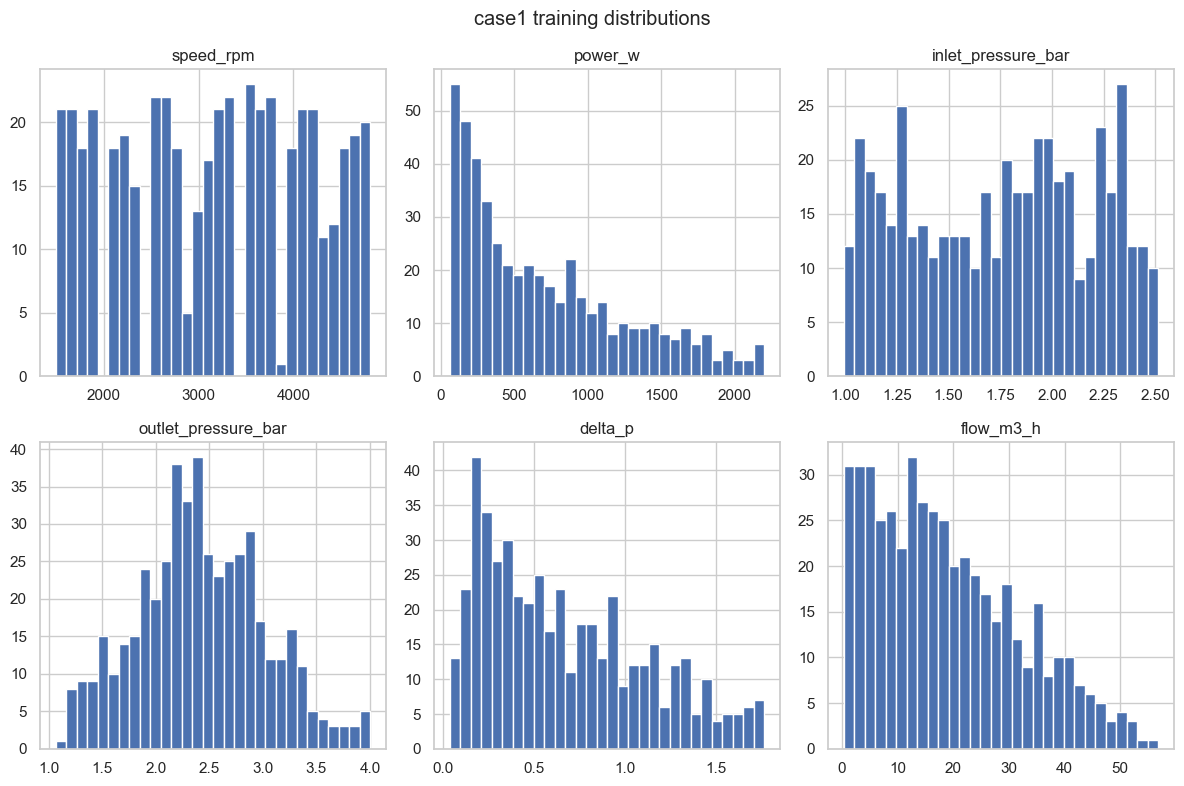

In [12]:
# case1 feature distributions

eda1[features1].hist(bins=30, figsize=(12, 8), layout=(2, 3))
plt.suptitle('case1 training distributions')
plt.tight_layout()
plt.show()

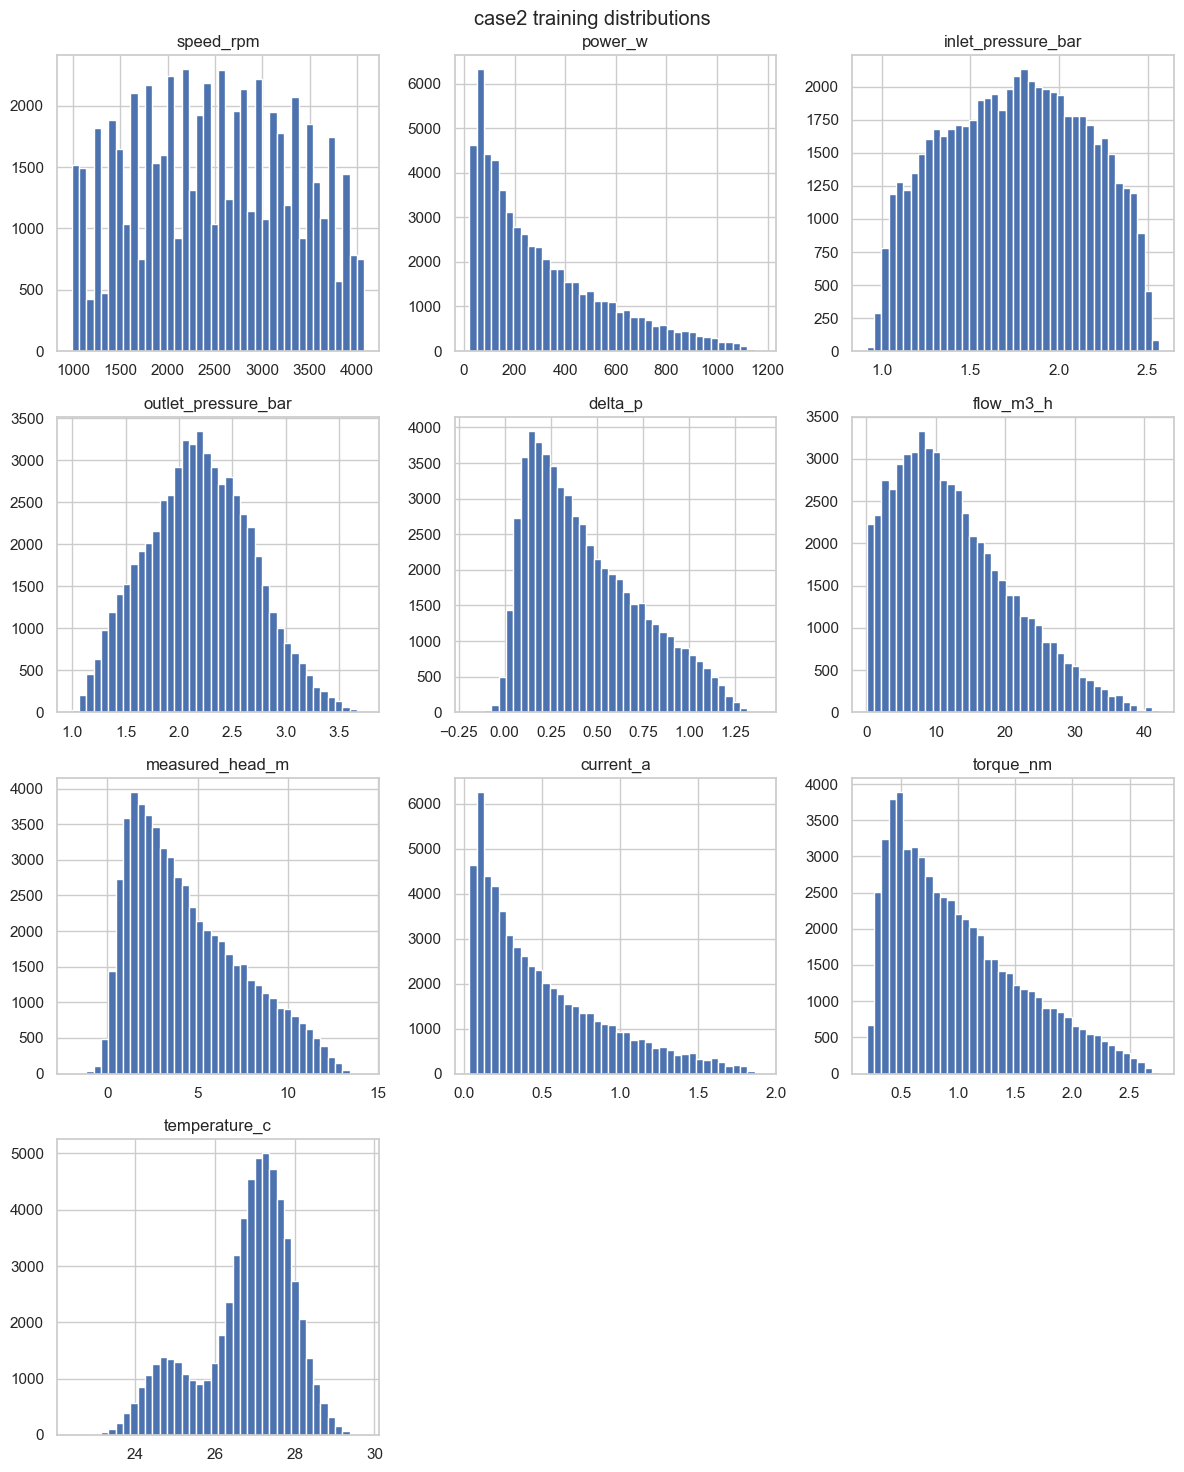

In [13]:
# case2 feature distributions

eda2[features2].hist(bins=40, figsize=(12, 15), layout=(4, 3))
plt.suptitle('case2 training distributions')
plt.tight_layout()
plt.show()

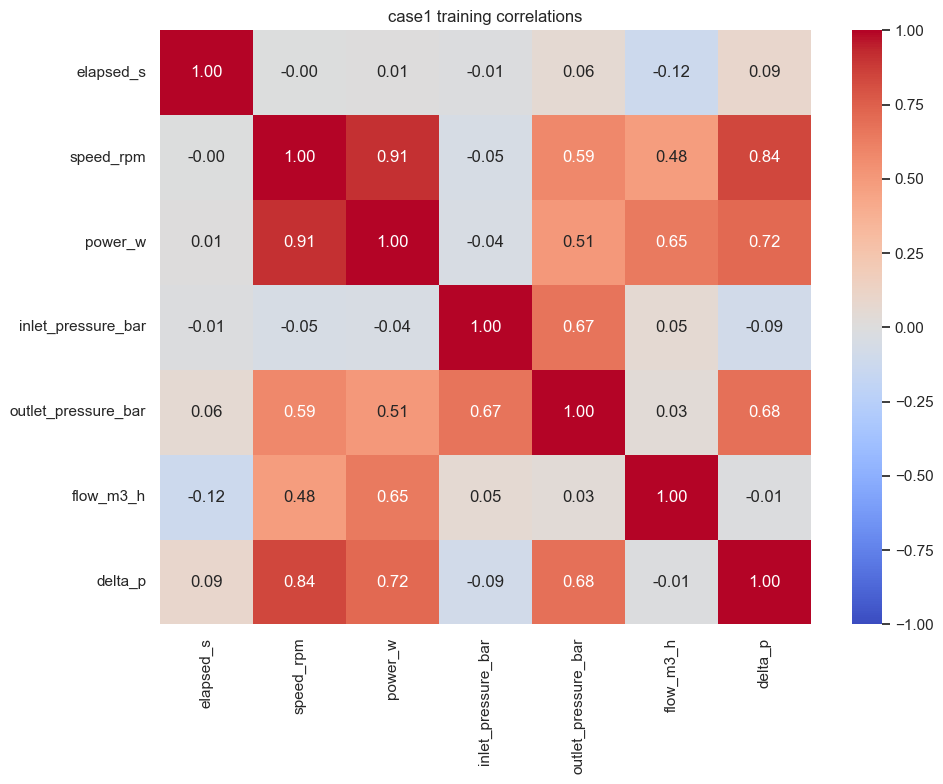

In [14]:
# case1 correlations

plt.figure(figsize=(10, 8))
sns.heatmap(eda1.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('case1 training correlations')
plt.tight_layout()
plt.show()

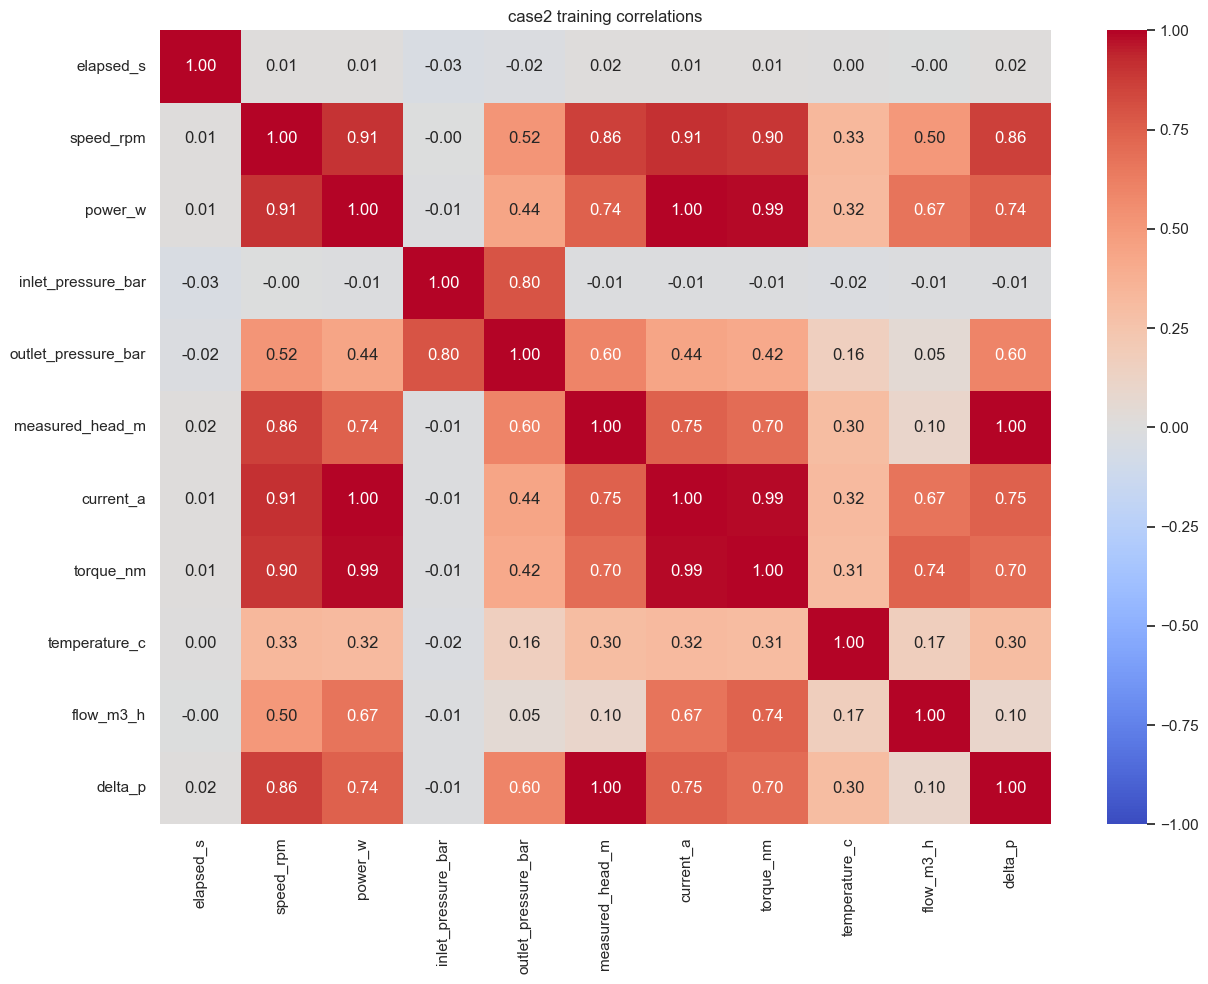

In [15]:
# case2 correlations

plt.figure(figsize=(13, 10))
sns.heatmap(eda2.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('case2 training correlations')
plt.tight_layout()
plt.show()

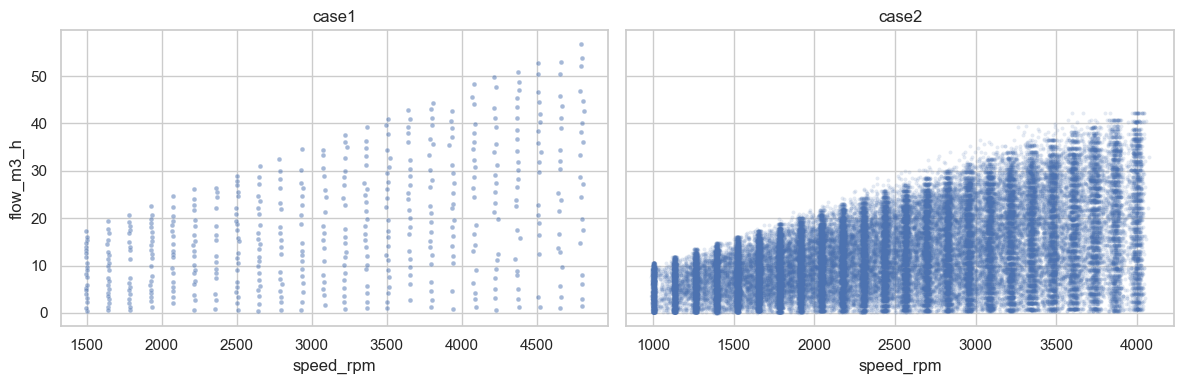

In [16]:
# flow against speed_rpm

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.scatterplot(data=eda1, x='speed_rpm', y='flow_m3_h', s=12, alpha=0.5, ax=axes[0])
sns.scatterplot(data=eda2, x='speed_rpm', y='flow_m3_h', s=8, alpha=0.15, linewidth=0, rasterized=True, ax=axes[1])
axes[0].set_title('case1')
axes[1].set_title('case2')
plt.tight_layout()
plt.show()

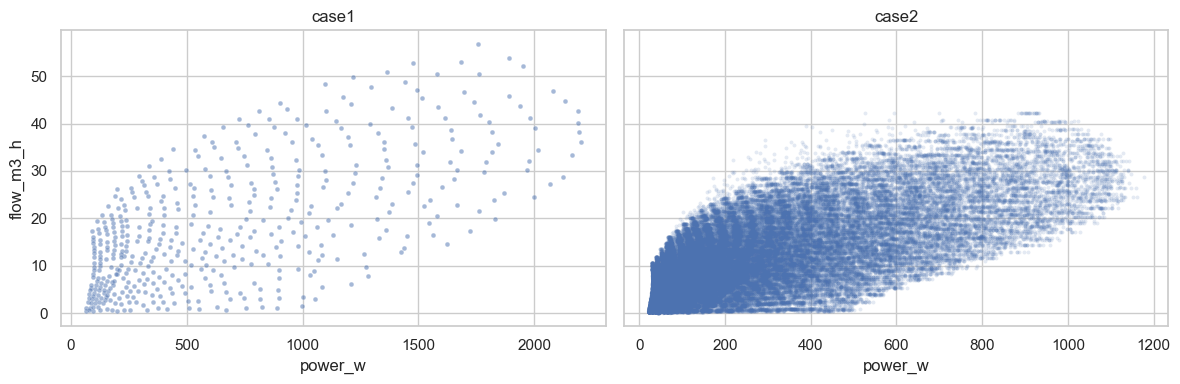

In [17]:
# flow against power_w

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.scatterplot(data=eda1, x='power_w', y='flow_m3_h', s=12, alpha=0.5, ax=axes[0])
sns.scatterplot(data=eda2, x='power_w', y='flow_m3_h', s=8, alpha=0.15, linewidth=0, rasterized=True, ax=axes[1])
axes[0].set_title('case1')
axes[1].set_title('case2')
plt.tight_layout()
plt.show()

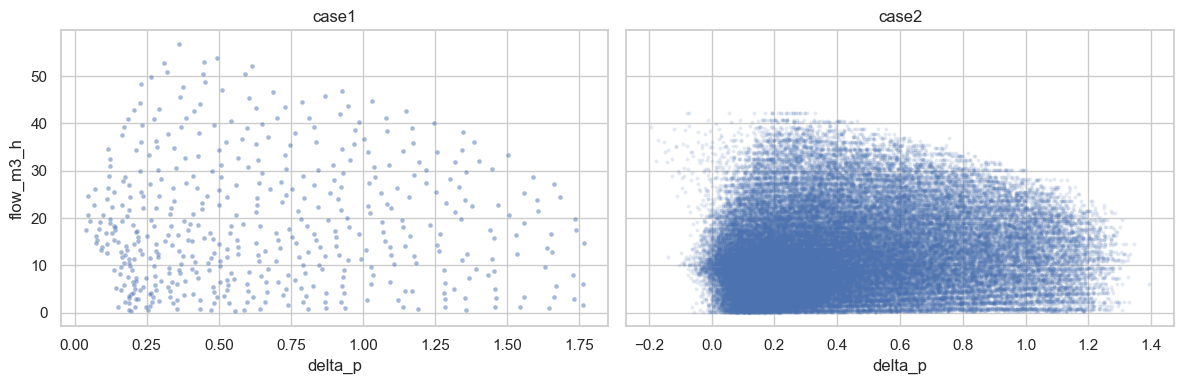

In [18]:
# flow against delta_p

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.scatterplot(data=eda1, x='delta_p', y='flow_m3_h', s=12, alpha=0.5, ax=axes[0])
sns.scatterplot(data=eda2, x='delta_p', y='flow_m3_h', s=8, alpha=0.15, linewidth=0, rasterized=True, ax=axes[1])
axes[0].set_title('case1')
axes[1].set_title('case2')
plt.tight_layout()
plt.show()

,rows
pump_id,
99223362_model_01,11990
99223362_model_02,11990
99223362_model_03,11990
99223362_model_04,11990
99223362_model_05,11990


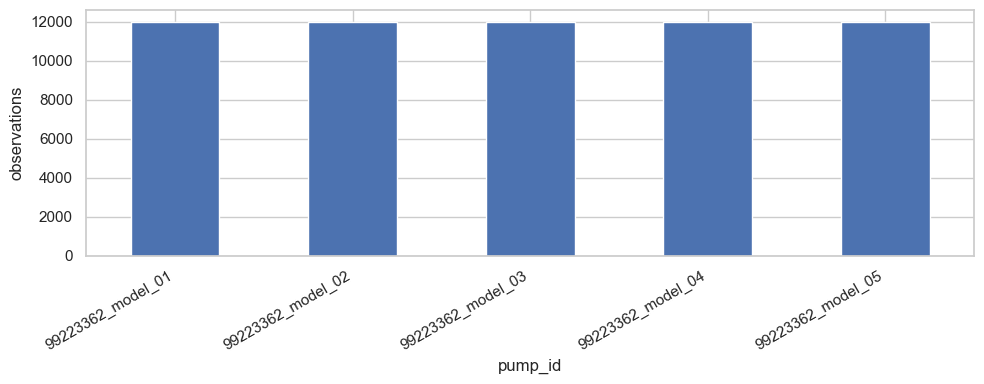

In [19]:
# observations per pump

pump_counts = eda2['pump_id'].value_counts().sort_index()
display(pump_counts.rename('rows').to_frame())
pump_counts.plot.bar(figsize=(10, 4))
plt.ylabel('observations')
plt.xlabel('pump_id')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

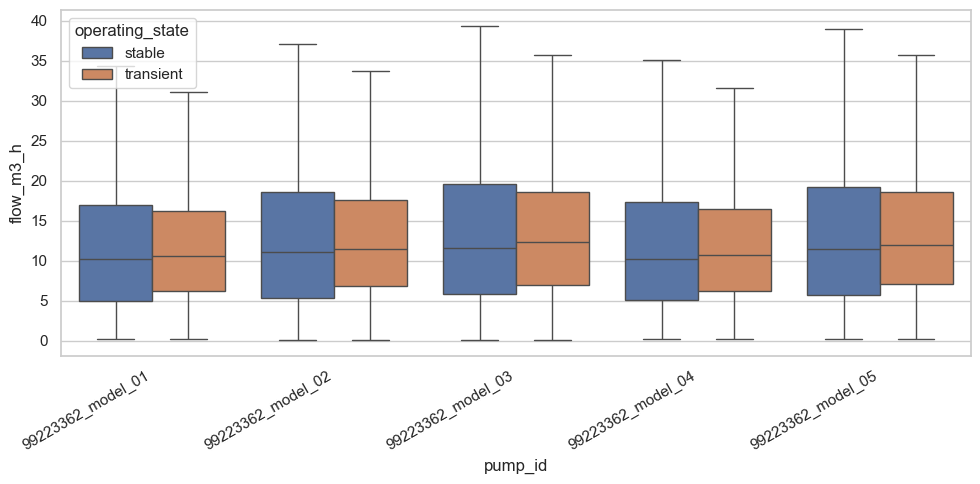

In [20]:
# flow distributions per pump

plt.figure(figsize=(10, 5))
sns.boxplot(data=eda2, x='pump_id', y='flow_m3_h', hue='operating_state', showfliers=False)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [21]:
# operating ranges per pump

pump_ranges = eda2.groupby('pump_id')[features2].agg(['min', 'max'])
display(pump_ranges)

speed_rpm                 power_w               \
                          min          max        min          max   
pump_id                                                              
99223362_model_01  989.025809  4043.043400  22.329953  1160.329409   
99223362_model_02  991.742331  4060.240837  21.634588  1143.080143   
99223362_model_03  988.945146  4056.523362  21.804092  1139.423038   
99223362_model_04  991.950889  4076.533053  21.441363  1176.803738   
99223362_model_05  990.579381  4050.810299  22.127703  1140.622138   

                  inlet_pressure_bar           outlet_pressure_bar            \
                                 min       max                 min       max   
pump_id                                                                        
99223362_model_01           0.921979  2.563669            1.021991  3.692986   
99223362_model_02           0.916196  2.548982            1.040529  3.632890   
99223362_model_03           0.920849  2.566167            1.004370  3.735367   
99223362_model_04           0.920703  2.557451            0.994336  3.641940   
99223362_model_05           0.936827  2.564196            1.039634  3.713697   

                    delta_p           flow_m3_h            measured_head_m  \
                        min       max       min        max             min   
pump_id                                                                      
99223362_model_01 -0.178654  1.303375  0.204702  36.740890       -1.824424   
99223362_model_02 -0.119729  1.326651  0.066809  40.276549       -1.222683   
99223362_model_03 -0.191862  1.307201  0.150391  42.203174       -1.959310   
99223362_model_04 -0.151608  1.295352  0.182654  37.754554       -1.548228   
99223362_model_05 -0.112048  1.393506  0.205192  42.126703       -1.144243   

                             current_a           torque_nm            \
                         max       min       max       min       max   
pump_id                                                                
99223362_model_01  13.310149  0.037515  1.906824  0.214414  2.745073   
99223362_model_02  13.547841  0.036419  1.881449  0.214814  2.760727   
99223362_model_03  13.349221  0.035949  1.831217  0.212847  2.722745   
99223362_model_04  13.228210  0.035971  1.850219  0.208403  2.695056   
99223362_model_05  14.230571  0.036498  1.854507  0.205021  2.685450   

                  temperature_c             
                            min        max  
pump_id                                     
99223362_model_01     25.134161  29.659888  
99223362_model_02     22.404829  27.254545  
99223362_model_03     25.367514  29.745947  
99223362_model_04     24.720725  29.393930  
99223362_model_05     24.962293  29.581515

operating_state,stable,transient
pump_id,,
99223362_model_01,0.500417,0.499583
99223362_model_02,0.500417,0.499583
99223362_model_03,0.500417,0.499583
99223362_model_04,0.500417,0.499583
99223362_model_05,0.500417,0.499583


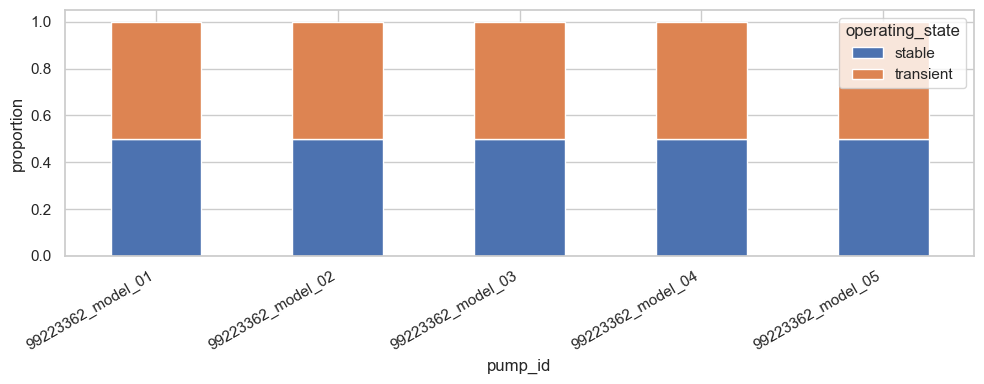

In [22]:
# operating-state proportions per pump

state_proportions = pd.crosstab(eda2['pump_id'], eda2['operating_state'], normalize='index')
display(state_proportions)
state_proportions.plot.bar(stacked=True, figsize=(10, 4))
plt.ylabel('proportion')
plt.xticks(rotation=30, ha='right')
plt.legend(title='operating_state')
plt.tight_layout()
plt.show()

In [23]:
# stable and transient statistics

display(eda2.groupby('operating_state')[features2].agg(['mean', 'std', 'min', 'median', 'max']))

speed_rpm                                       \
                        mean         std         min       median   
operating_state                                                     
stable           2502.011794  901.790793  988.945146  2503.094608   
transient        2502.045769  738.864046  990.579381  2500.068301   

                                 power_w                                     \
                         max        mean         std        min      median   
operating_state                                                               
stable           4076.533053  316.888424  273.099066  21.441363  226.686454   
transient        4041.466056  297.537911  223.019277  22.333645  234.901004   

                              ... torque_nm                                \
                         max  ...      mean       std       min    median   
operating_state               ...                                           
stable           1176.803738  ...  1.012877  0.608107  0.205021  0.859291   
transient        1143.080143  ...  1.000908  0.508012  0.208403  0.895559   

                          temperature_c                                  \
                      max          mean       std        min     median   
operating_state                                                           
stable           2.760727     26.774317  1.198174  22.404829  27.019758   
transient        2.726866     26.742741  1.169205  22.585503  27.007936   

                            
                       max  
operating_state             
stable           29.625553  
transient        29.745947  

[2 rows x 50 columns]

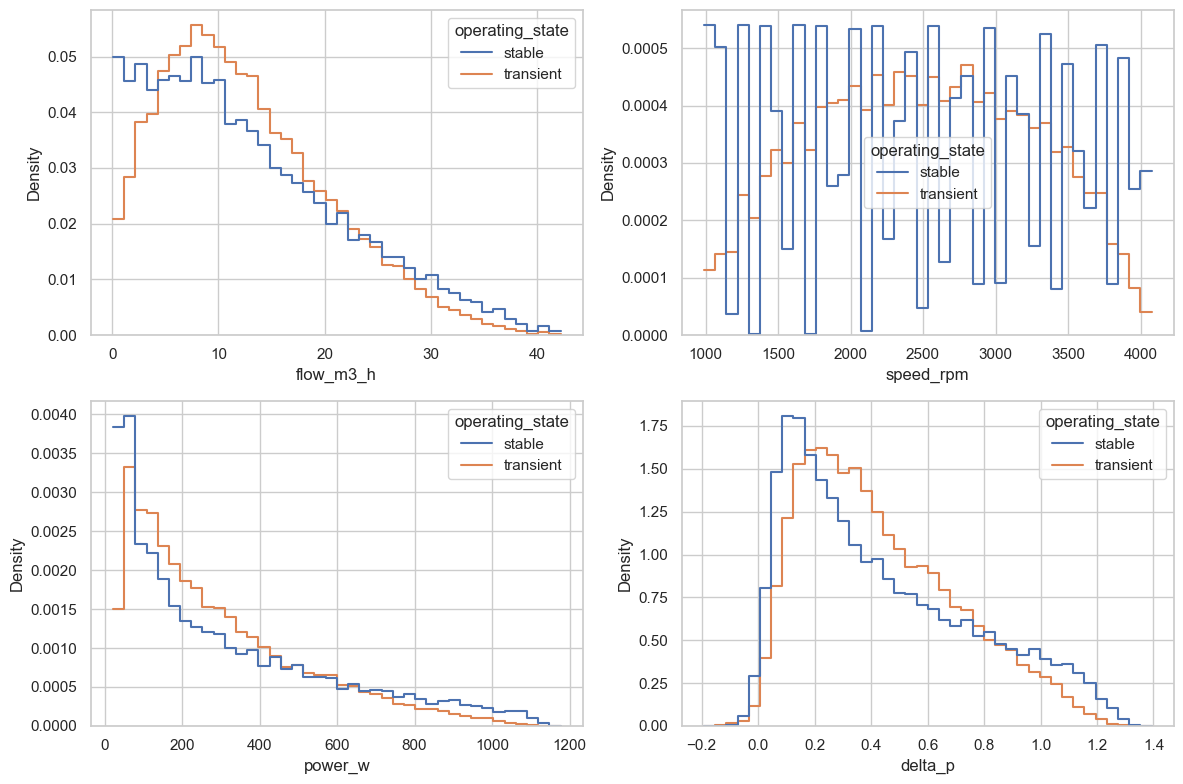

In [24]:
# stable and transient distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(['flow_m3_h', 'speed_rpm', 'power_w', 'delta_p'], axes.flat):
    sns.histplot(data=eda2, x=feature, hue='operating_state', bins=40, stat='density', common_norm=False, element='step', fill=False, ax=ax)
plt.tight_layout()
plt.show()

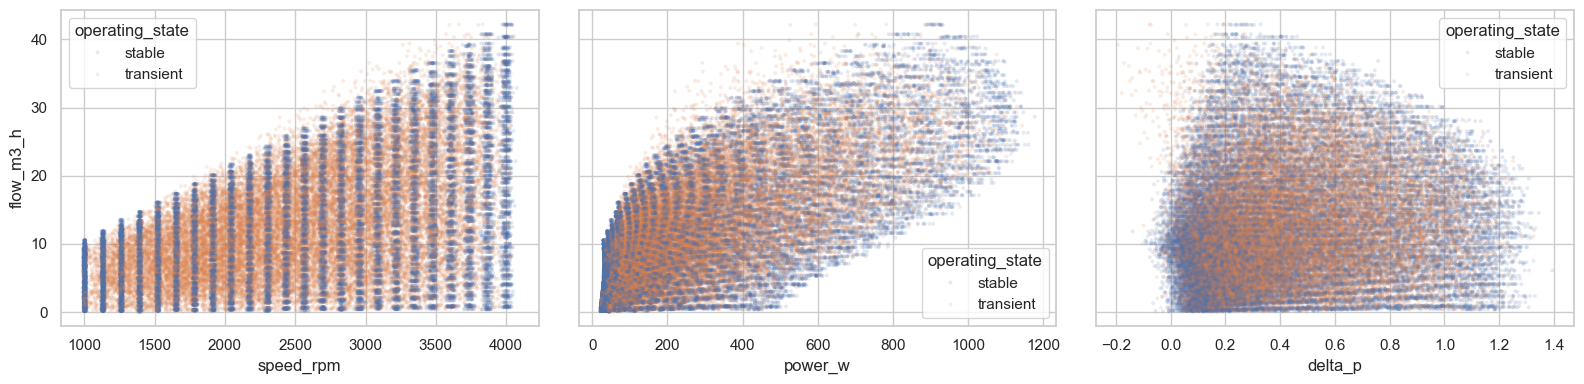

In [25]:
# stable and transient flow relationships

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for feature, ax in zip(['speed_rpm', 'power_w', 'delta_p'], axes):
    sns.scatterplot(data=eda2, x=feature, y='flow_m3_h', hue='operating_state', s=8, alpha=0.15, linewidth=0, rasterized=True, ax=ax)
plt.tight_layout()
plt.show()

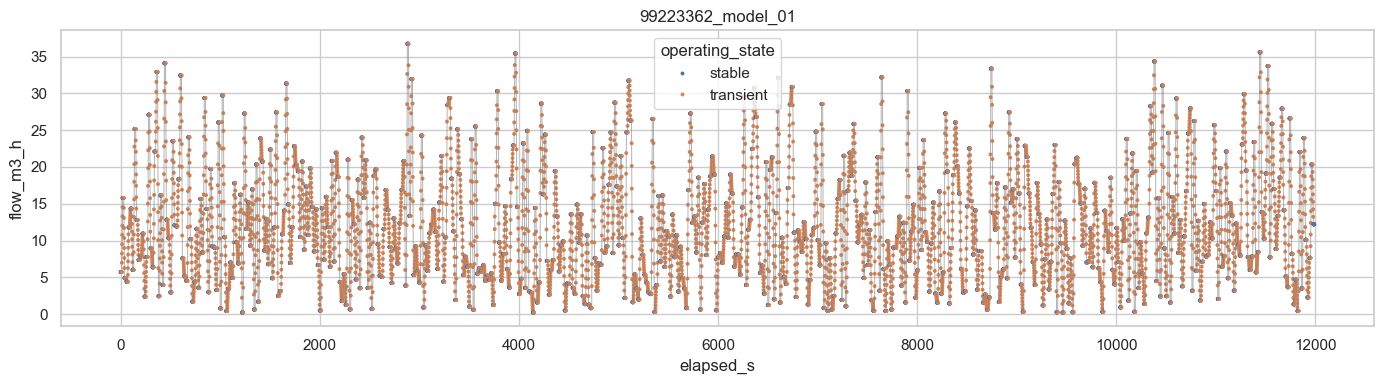

In [26]:
# flow over time for one pump

pump_id = eda2['pump_id'].iloc[0]
pump_data = eda2[eda2['pump_id'] == pump_id].sort_values('elapsed_s')

plt.figure(figsize=(14, 4))
plt.plot(pump_data['elapsed_s'], pump_data['flow_m3_h'], color='grey', linewidth=0.7, alpha=0.6)
sns.scatterplot(data=pump_data, x='elapsed_s', y='flow_m3_h', hue='operating_state', s=8, linewidth=0)
plt.title(pump_id)
plt.tight_layout()
plt.show()

In [27]:
# case comparison data

case_data = pd.concat([eda1[features1].assign(case='case1'), eda2[features1].assign(case='case2')], ignore_index=True)
stable_data = pd.concat([eda1[features1].assign(case='case1'), eda2.loc[eda2['operating_state'] == 'stable', features1].assign(case='case2')], ignore_index=True)

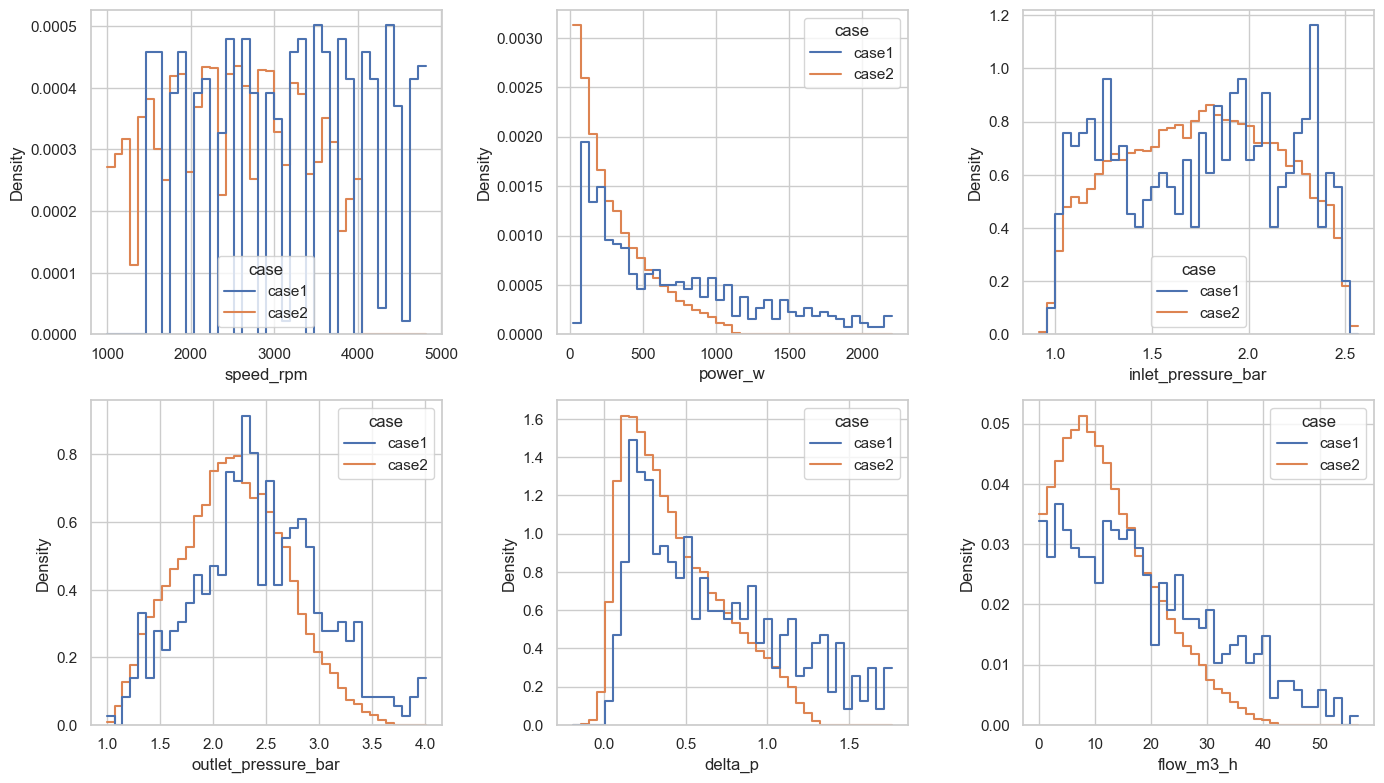

In [28]:
# feature distributions across cases

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for feature, ax in zip(features1, axes.flat):
    sns.histplot(data=case_data, x=feature, hue='case', bins=40, stat='density', common_norm=False, element='step', fill=False, ax=ax)
plt.tight_layout()
plt.show()

In [29]:
# operating ranges across cases and states

display(pd.concat({
    'case1 stable': eda1[features1].agg(['min', 'max']).T,
    'case2 stable': eda2.loc[eda2['operating_state'] == 'stable', features1].agg(['min', 'max']).T,
    'case2 transient': eda2.loc[eda2['operating_state'] == 'transient', features1].agg(['min', 'max']).T
}, names=['case and state', 'feature']))

min          max
case and state  feature                                      
case1 stable    speed_rpm            1494.159036  4813.199117
                power_w                63.185204  2201.655665
                inlet_pressure_bar      0.993489     2.514032
                outlet_pressure_bar     1.067458     4.003231
                delta_p                 0.039170     1.764468
                flow_m3_h               0.354386    56.823209
case2 stable    speed_rpm             988.945146  4076.533053
                power_w                21.441363  1176.803738
                inlet_pressure_bar      0.916196     2.566167
                outlet_pressure_bar     0.994336     3.713697
                delta_p                -0.138333     1.393506
                flow_m3_h               0.066809    42.203174
case2 transient speed_rpm             990.579381  4041.466056
                power_w                22.333645  1143.080143
                inlet_pressure_bar      0.938251     2.564196
                outlet_pressure_bar     1.025890     3.735367
                delta_p                -0.191862     1.333447
                flow_m3_h               0.066809    42.203174

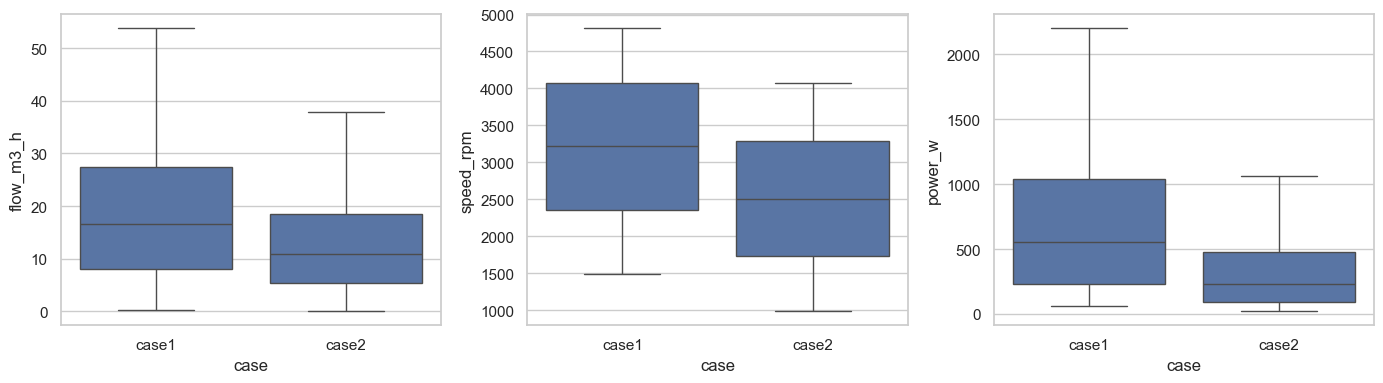

In [30]:
# stable observations across cases

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feature, ax in zip(['flow_m3_h', 'speed_rpm', 'power_w'], axes):
    sns.boxplot(data=stable_data, x='case', y=feature, showfliers=False, ax=ax)
plt.tight_layout()
plt.show()